<a href="https://colab.research.google.com/github/faheem1867/cryptocurrency-price-prediction-lstm/blob/main/Cryptocurrency_Closing_Price_Prediction_using_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install kagglehub tensorflow scikit-learn matplotlib pandas numpy

In [2]:
import os
import glob
import pandas as pd
import numpy as np

csv_path = None

try:
    import kagglehub

    folder = kagglehub.dataset_download(
        "sudalairajkumar/cryptocurrencypricehistory"
    )

    files = glob.glob(
        os.path.join(folder, "**", "*.csv"),
        recursive=True
    )

    bitcoin_files = [
        f for f in files
        if "bitcoin" in os.path.basename(f).lower()
    ]

    if bitcoin_files:
        csv_path = bitcoin_files[0]
        print("Dataset downloaded successfully:", csv_path)

except Exception as e:
    print("Automatic download failed. Please upload the CSV file.")
    print("Reason:", str(e)[:250])

if csv_path is None:
    from google.colab import files

    uploaded = files.upload()

    csv_files = [
        f for f in uploaded.keys()
        if f.lower().endswith(".csv")
    ]

    if not csv_files:
        raise ValueError("Please upload a CSV file.")

    csv_path = csv_files[0]

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())
print("Columns:", df.columns.tolist())

100%|██████████| 1.70M/1.70M [00:00<00:00, 101MB/s]

Extracting files...
Dataset downloaded successfully: /root/.cache/kagglehub/datasets/sudalairajkumar/cryptocurrencypricehistory/versions/3/coin_Bitcoin.csv
Dataset loaded successfully!
Dataset shape: (2991, 10)
   SNo     Name Symbol                 Date        High         Low  \
0    1  Bitcoin    BTC  2013-04-29 23:59:59  147.488007  134.000000   
1    2  Bitcoin    BTC  2013-04-30 23:59:59  146.929993  134.050003   
2    3  Bitcoin    BTC  2013-05-01 23:59:59  139.889999  107.720001   
3    4  Bitcoin    BTC  2013-05-02 23:59:59  125.599998   92.281898   
4    5  Bitcoin    BTC  2013-05-03 23:59:59  108.127998   79.099998   

         Open       Close  Volume     Marketcap  
0  134.444000  144.539993     0.0  1.603769e+09  
1  144.000000  139.000000     0.0  1.542813e+09  
2  139.000000  116.989998     0.0  1.298955e+09  
3  116.379997  105.209999     0.0  1.168517e+09  
4  106.250000   97.750000     0.0  1.085995e+09  
Columns: ['SNo', 'Name', 'Symbol', 'Date', 'High', 'Low', 'Ope

In [3]:
# Standardize column names
df.columns = [
    str(c).strip().lower().replace(" ", "_")
    for c in df.columns
]

# Find date and closing-price columns
date_col = next(
    (c for c in df.columns if c in ["date", "timestamp", "time"]),
    None
)

close_col = next(
    (c for c in df.columns if c in ["close", "closing_price", "close_price"]),
    None
)

if date_col is None or close_col is None:
    raise ValueError(
        f"Date or closing-price column not found. Columns: {df.columns.tolist()}"
    )

# Convert columns to correct data types
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df[close_col] = pd.to_numeric(
    df[close_col].astype(str).str.replace(",", "", regex=False)
      .str.replace("$", "", regex=False),
    errors="coerce"
)

# Remove invalid dates and sort chronologically
df = df.dropna(subset=[date_col])
df = df.sort_values(date_col)

# Keep one closing price per day
df = df[[date_col, close_col]].dropna(subset=[close_col])
df = df.drop_duplicates(subset=[date_col], keep="last")
df = df.set_index(date_col).sort_index()

# Ensure a daily timeline and fill missing closing-price values
df = df.resample("D").last()
df[close_col] = df[close_col].interpolate(method="time")

# Select the latest 2000 consecutive calendar days
df = df.dropna(subset=[close_col]).tail(2000).copy()

if len(df) < 100:
    raise ValueError("Not enough daily records. Please check the dataset.")

df = df.rename(columns={close_col: "Close"})

print("Selected records:", len(df))
print("Start date:", df.index.min().date())
print("End date:", df.index.max().date())
print("Missing values:", df["Close"].isna().sum())

display(df.head())
display(df.tail())

Selected records: 2000
Start date: 2016-01-15
End date: 2021-07-06
Missing values: 0


,Close
date,
2016-01-15,364.330994
2016-01-16,387.536011
2016-01-17,382.299011
2016-01-18,387.167999
2016-01-19,380.148987


,Close
date,
2021-07-02,33897.048590
2021-07-03,34668.548402
2021-07-04,35287.779766
2021-07-05,33746.002456
2021-07-06,34235.193451


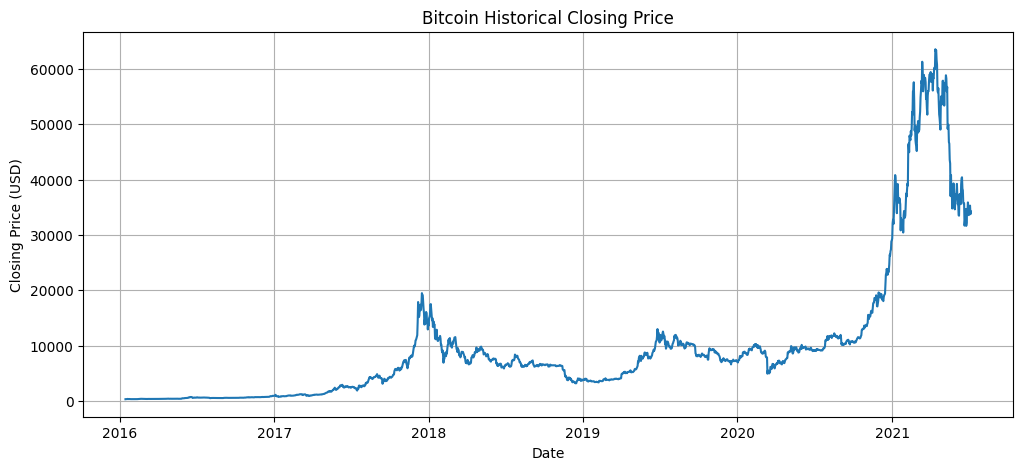

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df.index, df["Close"])
plt.title("Bitcoin Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.grid(True)
plt.show()

In [6]:
from sklearn.preprocessing import MinMaxScaler

values = df[["Close"]].values.astype("float32")

# Chronological 80:20 split
split = int(len(values) * 0.80)

# Fit scaler only on training data
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(values[:split])

scaled_values = scaler.transform(values)

# Use previous 7 days to predict the next day
window_size = 7

X_train, y_train = [], []
X_test, y_test = [], []

for i in range(window_size, len(scaled_values)):
    X_seq = scaled_values[i-window_size:i]
    y_value = scaled_values[i, 0]

    if i < split:
        X_train.append(X_seq)
        y_train.append(y_value)
    else:
        X_test.append(X_seq)
        y_test.append(y_value)

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1593, 7, 1)
y_train shape: (1593,)
X_test shape: (400, 7, 1)
y_test shape: (400,)


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model = Sequential([
    tf.keras.Input(shape=(7, 1)),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed!")

Epoch 1/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0087 - val_loss: 0.0023
Epoch 2/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0055 - val_loss: 0.0020
Epoch 3/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0021 - val_loss: 0.0012
Epoch 4/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0020 - val_loss: 8.8343e-04
Epoch 5/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0018 - val_loss: 8.2809e-04
Epoch 6/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0016 - val_loss: 8.6726e-04
Epoch 7/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0015 - val_loss: 8.8849e-04
Epoch 8/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0014 - val_loss: 7.8619e-04
Epoch 9/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0013 - val_loss: 0.0010
Epoch 10/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0013 - val_loss: 8.1146e-04
Epoch 11/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0018 - val_loss: 9.5631e-04
Epoch 12/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict unseen test sequences
pred_scaled = model.predict(X_test, verbose=0)

# Convert predictions back to original USD prices
y_test_usd = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

pred_usd = scaler.inverse_transform(
    pred_scaled
).flatten()

mae = mean_absolute_error(y_test_usd, pred_usd)
rmse = np.sqrt(mean_squared_error(y_test_usd, pred_usd))

print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")

Mean Absolute Error (MAE): $4,192.37
Root Mean Squared Error (RMSE): $6,376.85


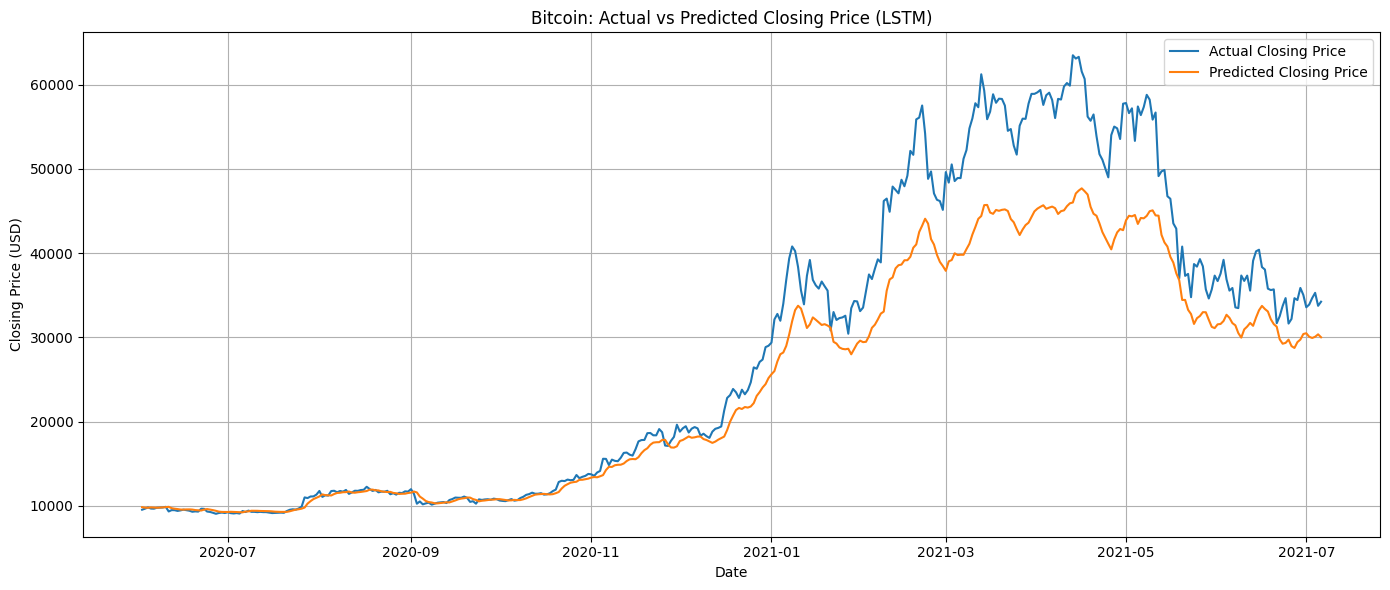

In [11]:
test_dates = df.index[split:]

plt.figure(figsize=(14, 6))
plt.plot(test_dates, y_test_usd, label="Actual Closing Price")
plt.plot(test_dates, pred_usd, label="Predicted Closing Price")

plt.title("Bitcoin: Actual vs Predicted Closing Price (LSTM)")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Close_USD": y_test_usd,
    "Predicted_Close_USD": pred_usd
})

results["Absolute_Error"] = abs(
    results["Actual_Close_USD"] -
    results["Predicted_Close_USD"]
)

print("First 10 unseen test predictions:")
display(results.head(10).round(2))

First 10 unseen test predictions:


,Date,Actual_Close_USD,Predicted_Close_USD,Absolute_Error
0,2020-06-02,9529.799805,9831.429688,301.630005
1,2020-06-03,9656.719727,9770.320312,113.599998
2,2020-06-04,9800.639648,9763.980469,36.660000
3,2020-06-05,9665.530273,9805.070312,139.539993
4,2020-06-06,9653.679688,9784.290039,130.610001
5,2020-06-07,9758.849609,9764.280273,5.420000
6,2020-06-08,9771.490234,9786.200195,14.710000
7,2020-06-09,9795.700195,9808.059570,12.360000
8,2020-06-10,9870.099609,9832.379883,37.709999
9,2020-06-11,9321.780273,9873.690430,551.909973


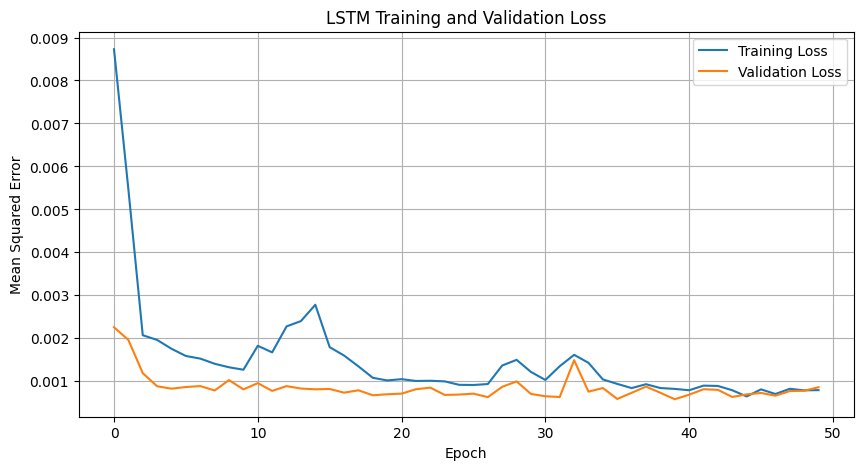

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
print("=" * 45)
print("CRYPTOCURRENCY PRICE PREDICTION")
print("=" * 45)
print("Cryptocurrency: Bitcoin")
print("Model: LSTM")
print("Input window: Previous 7 days")
print("Total records:", len(df))
print("Training records:", split)
print("Testing records:", len(values) - split)
print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print("\nSample predictions:")
display(results.tail(5).round(2))
print("Project completed successfully!")

CRYPTOCURRENCY PRICE PREDICTION
Cryptocurrency: Bitcoin
Model: LSTM
Input window: Previous 7 days
Total records: 2000
Training records: 1600
Testing records: 400
MAE: $4,192.37
RMSE: $6,376.85

Sample predictions:


,Date,Actual_Close_USD,Predicted_Close_USD,Absolute_Error
395,2021-07-02,33897.050781,30069.380859,3827.669922
396,2021-07-03,34668.550781,29925.589844,4742.959961
397,2021-07-04,35287.781250,30073.060547,5214.720215
398,2021-07-05,33746.000000,30357.980469,3388.020020
399,2021-07-06,34235.199219,30010.589844,4224.600098


Project completed successfully!


===== LSTM CRYPTOCURRENCY PREDICTION =====
Total records: 2000
Training records: 1593
Testing records: 400
MAE: $4,192.37
RMSE: $6,376.85


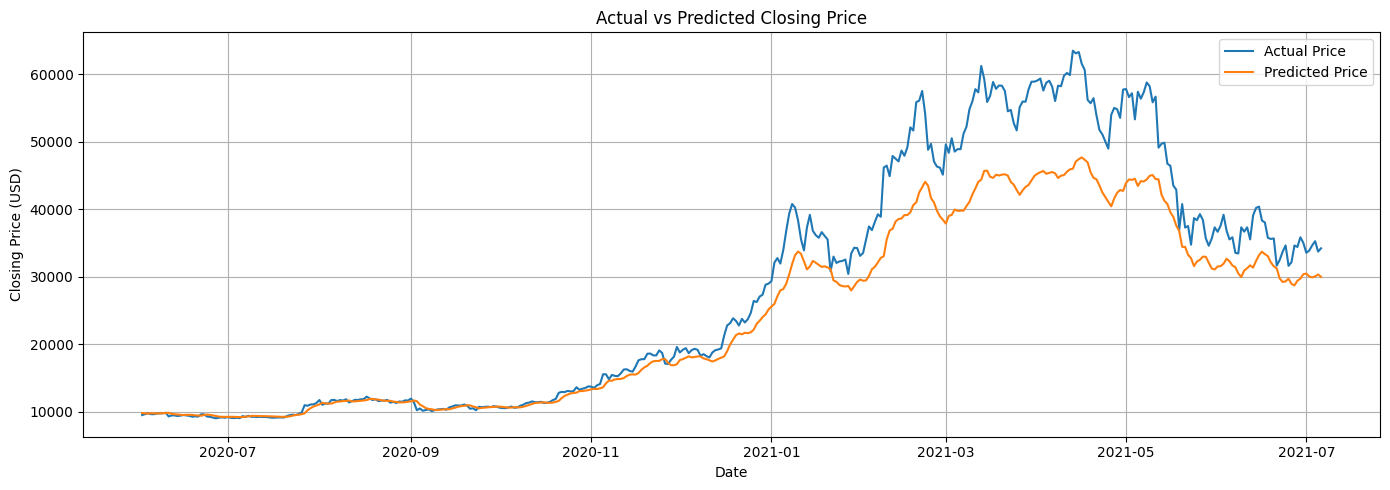

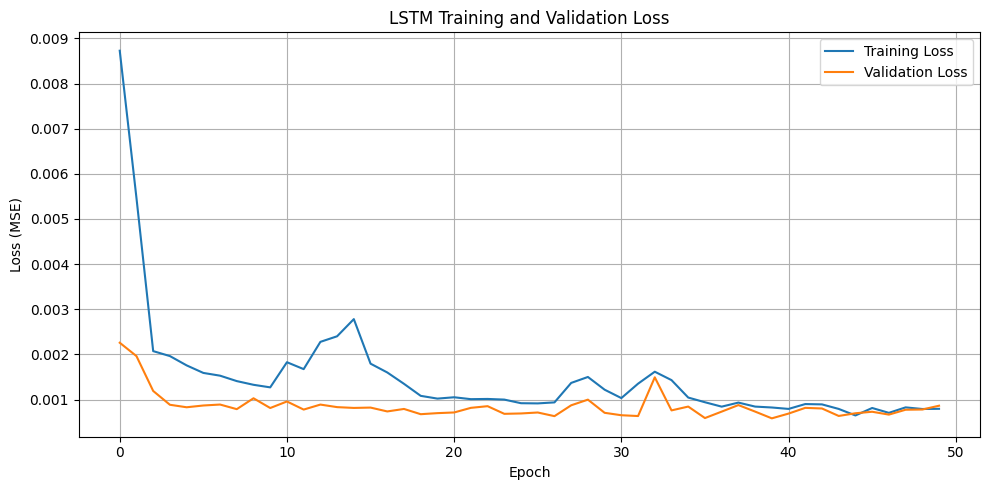


===== FIRST 10 TEST PREDICTIONS =====


,Date,Actual_Price,Predicted_Price,Absolute_Error
0,2020-06-02,9529.799805,9831.429688,301.630005
1,2020-06-03,9656.719727,9770.320312,113.599998
2,2020-06-04,9800.639648,9763.980469,36.660000
3,2020-06-05,9665.530273,9805.070312,139.539993
4,2020-06-06,9653.679688,9784.290039,130.610001
5,2020-06-07,9758.849609,9764.280273,5.420000
6,2020-06-08,9771.490234,9786.200195,14.710000
7,2020-06-09,9795.700195,9808.059570,12.360000
8,2020-06-10,9870.099609,9832.379883,37.709999
9,2020-06-11,9321.780273,9873.690430,551.909973


In [15]:

# FINAL OUTPUT: Evaluation + Graphs + Predictions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Calculate evaluation metrics
actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

predicted = scaler.inverse_transform(
    model.predict(X_test, verbose=0)
).flatten()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("===== LSTM CRYPTOCURRENCY PREDICTION =====")
print("Total records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")

# 2. Actual vs Predicted Graph
test_dates = df.index[-len(actual):]

plt.figure(figsize=(14, 5))
plt.plot(test_dates, actual, label="Actual Price")
plt.plot(test_dates, predicted, label="Predicted Price")
plt.title("Actual vs Predicted Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Training vs Validation Loss Graph
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Show unseen test predictions
results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Price": actual,
    "Predicted_Price": predicted
})
results["Absolute_Error"] = abs(
    results["Actual_Price"] - results["Predicted_Price"]
)

print("\n===== FIRST 10 TEST PREDICTIONS =====")
display(results.head(10).round(2))
